In [5]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 100
shap.initjs()

RANDOM_STATE = 42

In [6]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/credit-risk
import os
print(os.getcwd())
os.listdir('.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/credit-risk
/content/drive/MyDrive/credit-risk


['data', 'models', 'reports', 'src', 'notebooks', 'configs']

In [7]:
!pip install catboost --quiet

xgb_model = joblib.load('models/xgb_best.pkl')
lgbm_model = joblib.load('models/lgbm_best.pkl')
cat_model = joblib.load('models/cat_best.pkl')
meta_model = joblib.load('models/meta_model.pkl')

df = pd.read_csv('data/processed/df_selected.csv')
print(df.shape)
df.head()

(150000, 12)


,RevolvingUtilizationOfUnsecuredLines,age,DebtRatio,NumberOfOpenCreditLinesAndLoans,NumberRealEstateLoansOrLines,NumberOfDependents,income_missing,DebtToIncomeRatio,IncomePerDependent,TotalLatePayments,LatePaymentRatio,SeriousDlqin2yrs
0,0.766127,45.0,0.802982,13,6,2.0,0,8.803663e-05,3040.0,2,0.142857,1
1,0.957151,40.0,0.121876,4,0,1.0,0,4.685744e-05,1300.0,0,0.000000,0
2,0.658180,38.0,0.085113,2,0,0.0,0,2.797022e-05,3042.0,2,0.666667,0
3,0.233810,30.0,0.036050,5,0,0.0,0,1.092084e-05,3300.0,0,0.000000,0
4,0.907239,49.0,0.024926,7,1,0.0,0,9.969879e-07,25000.0,1,0.125000,0


In [8]:
from sklearn.model_selection import train_test_split

TARGET = 'SeriousDlqin2yrs'
FEATURES = [c for c in df.columns if c != TARGET]

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(120000, 11) (30000, 11)


In [9]:
print(xgb_model.get_params()['n_estimators'])
print(xgb_model.get_params()['max_depth'])

291
10


In [10]:
SAMPLE_SIZE = 5000
X_test_sample = X_test.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE)

explainer_xgb = shap.TreeExplainer(xgb_model)
shap_values_xgb = explainer_xgb.shap_values(X_test_sample)

print(shap_values_xgb.shape)

(5000, 11)


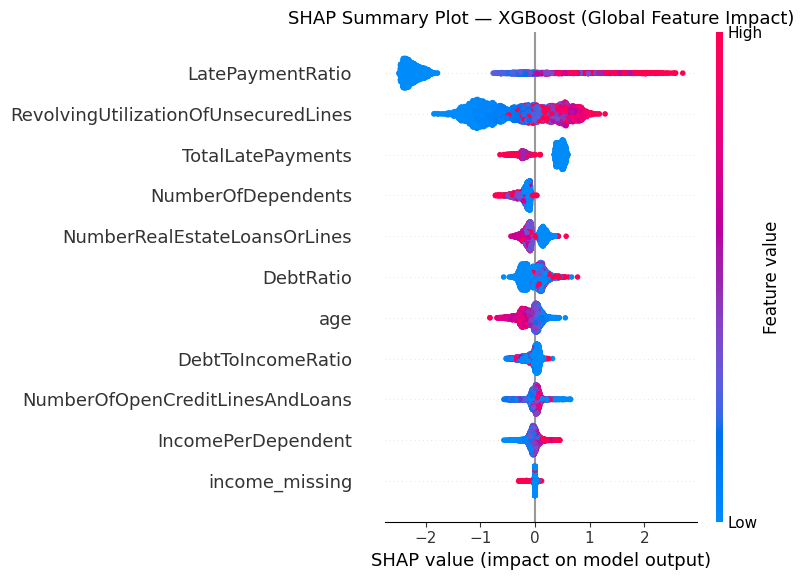

In [11]:
fig = plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values_xgb, X_test_sample, show=False)
plt.title("SHAP Summary Plot — XGBoost (Global Feature Impact)", fontsize=13)
plt.tight_layout()
plt.savefig("reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

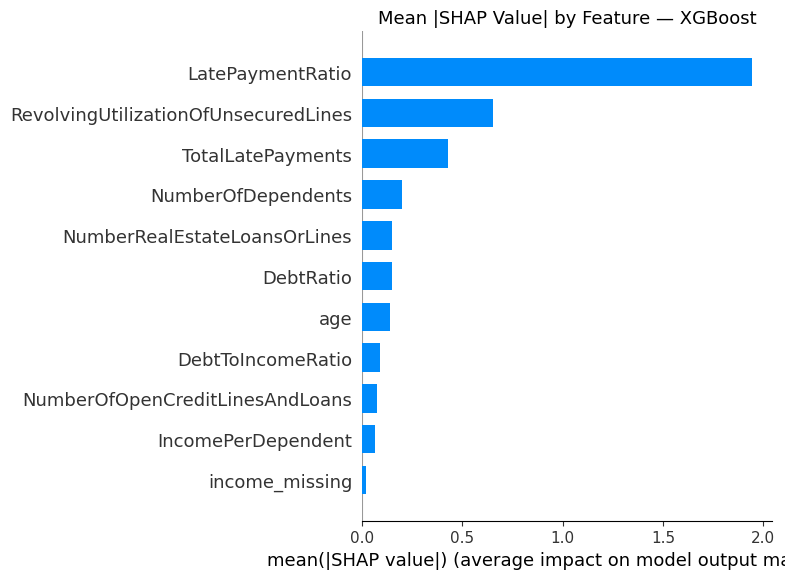

In [12]:
fig = plt.figure(figsize=(9, 6))
shap.summary_plot(shap_values_xgb, X_test_sample, plot_type="bar", show=False)
plt.title("Mean |SHAP Value| by Feature — XGBoost", fontsize=13)
plt.tight_layout()
plt.savefig("reports/figures/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

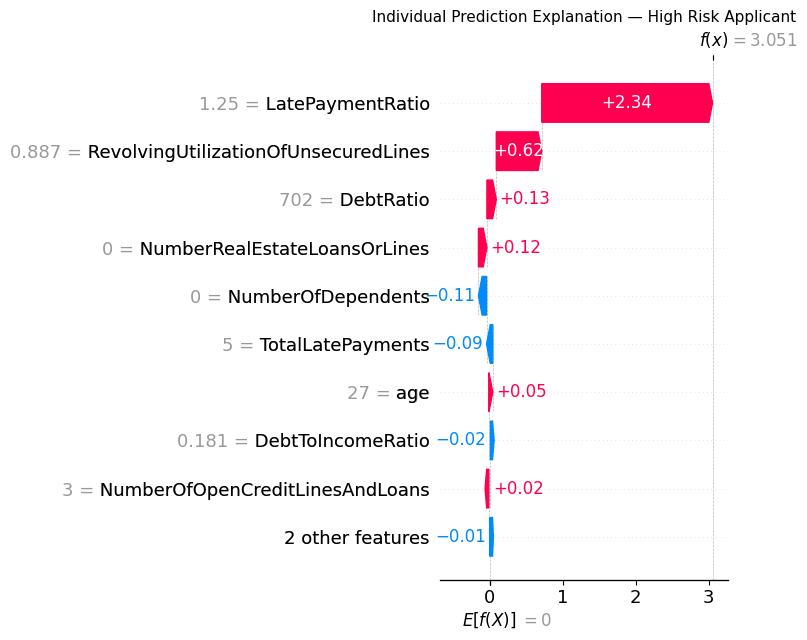

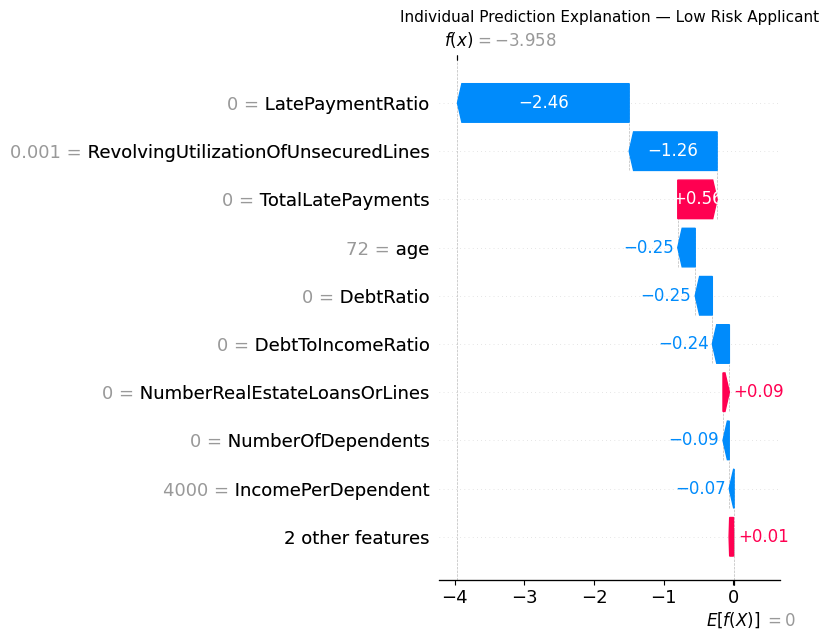

In [14]:
explainer_obj = explainer_xgb(X_test_sample)

high_risk_idx = np.argmax(shap_values_xgb.sum(axis=1))
low_risk_idx = np.argmin(shap_values_xgb.sum(axis=1))

for label, idx in [("high_risk", high_risk_idx), ("low_risk", low_risk_idx)]:
    plt.figure(figsize=(9, 6))
    shap.plots.waterfall(explainer_obj[idx], show=False)
    plt.title(f"Individual Prediction Explanation — {label.replace('_', ' ').title()} Applicant", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"reports/figures/waterfall_{label}.png", dpi=150, bbox_inches="tight")
    plt.show()

['LatePaymentRatio', 'RevolvingUtilizationOfUnsecuredLines', 'TotalLatePayments', 'NumberOfDependents', 'NumberRealEstateLoansOrLines', 'DebtRatio']


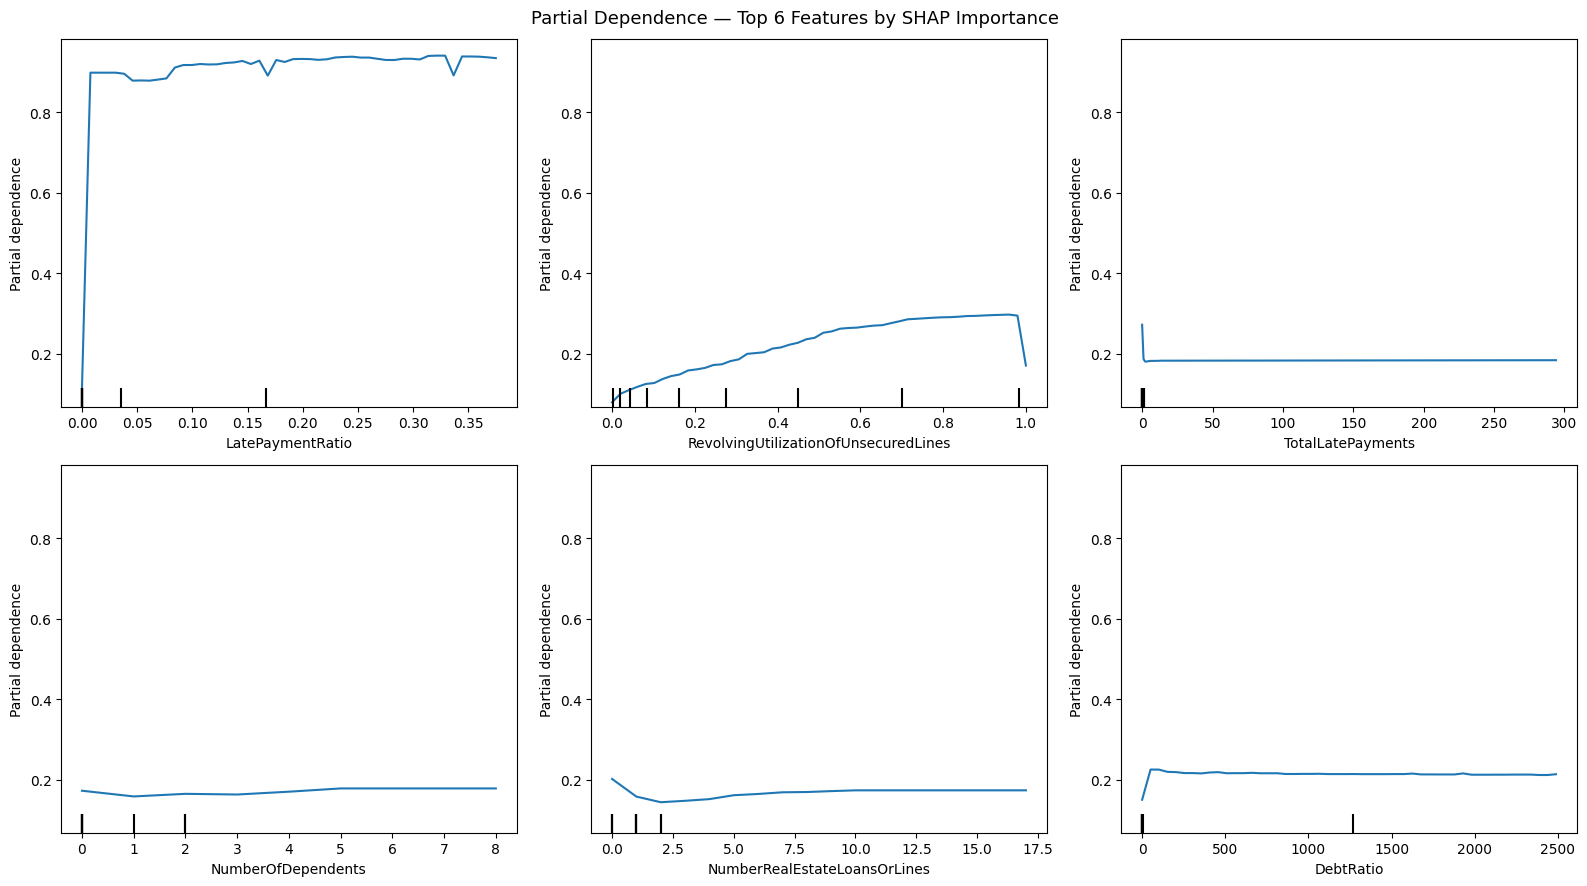

In [15]:
from sklearn.inspection import PartialDependenceDisplay

mean_abs_shap = np.abs(shap_values_xgb).mean(axis=0)
top_features = X_test_sample.columns[np.argsort(mean_abs_shap)[::-1][:6]].tolist()
print(top_features)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
PartialDependenceDisplay.from_estimator(
    xgb_model,
    X_test_sample,
    features=top_features,
    ax=ax.ravel()[:len(top_features)],
    grid_resolution=50
)
plt.suptitle("Partial Dependence — Top 6 Features by SHAP Importance", fontsize=13)
plt.tight_layout()
plt.savefig("reports/figures/pdp_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
import json

with open("configs/best_params.json") as f:
    best_params = json.load(f)

baseline_results = pd.read_csv("data/processed/baseline_results.csv")
print(baseline_results)
print(best_params.keys())
print(top_features)

               Model   ROC-AUC    PR-AUC        F1
0  CatBoost Baseline  0.853354  0.339503  0.397634
1   XGBoost Baseline  0.850634  0.338289  0.387404
2  LightGBM Baseline  0.850492  0.335837  0.372824
dict_keys(['xgb', 'lgbm', 'cat'])
['LatePaymentRatio', 'RevolvingUtilizationOfUnsecuredLines', 'TotalLatePayments', 'NumberOfDependents', 'NumberRealEstateLoansOrLines', 'DebtRatio']


In [18]:
X_stack_test = pd.read_csv("data/processed/X_stack_test.csv")
print(X_stack_test.shape)
print(X_stack_test.columns.tolist())

(30000, 3)
['xgb_pred', 'lgbm_pred', 'cat_pred']


In [19]:
# xgb_pred in X_stack_test should correlate strongly with xgb_model's own predictions on X_test,
# IF X_stack_test was built from the same X_test/y_test split as this notebook's Cell 4.
xgb_direct_proba = xgb_model.predict_proba(X_test)[:, 1]

import numpy as np
corr = np.corrcoef(X_stack_test['xgb_pred'].values, xgb_direct_proba)[0, 1]
print("Correlation between X_stack_test xgb_pred and xgb_model direct predict on in-memory X_test:", corr)

Correlation between X_stack_test xgb_pred and xgb_model direct predict on in-memory X_test: 0.994282157651922


In [20]:
diff = np.abs(X_stack_test['xgb_pred'].values - xgb_direct_proba)
print("Max abs diff:", diff.max())
print("Mean abs diff:", diff.mean())
print("Num rows with diff > 0.05:", (diff > 0.05).sum())
print("Num rows with diff > 0.2:", (diff > 0.2).sum())

Max abs diff: 0.3575187660753727
Mean abs diff: 0.012069968490093015
Num rows with diff > 0.05: 1111
Num rows with diff > 0.2: 5


In [21]:
import os
print(os.listdir("data/processed"))

['df_features.csv', 'df_selected.csv', 'df_log_features.csv', 'baseline_results.csv', 'X_stack_train.csv', 'X_stack_test.csv', 'oof_arrays.npz']


In [22]:
npz = np.load("data/processed/oof_arrays.npz")
print(npz.files)

['oof_xgb', 'oof_lgbm', 'oof_cat']


In [23]:
import json

with open("notebooks/05_hpo_ensemble.ipynb") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    src = "".join(cell.get("source", []))
    if "X_stack_test" in src or "train_test_split" in src:
        print(f"--- Cell {i} ---")
        print(src)
        print()

--- Cell 2 ---
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# --- Load selected features (for tree models) ---
df = pd.read_csv(f"{DATA_PROCESSED}/df_selected.csv")

X = df.drop(columns=['SeriousDlqin2yrs'])
y = df['SeriousDlqin2yrs']

# --- Train/test split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- SMOTE on training set only ---
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("X_train_sm shape:", X_train_sm.shape)
print("X_test shape:    ", X_test.shape)
print(f"Defaults in train after SMOTE: {y_train_sm.sum()} ({y_train_sm.mean()*100:.2f}%)")

--- Cell 3 ---
# --- Load log-transformed features (for logistic regression meta-learner) ---
df_log = pd.read_csv(f"{DATA_PROCESSED}/df_log_features.csv")

X_log = df_log.drop(columns=['SeriousDlqin2yrs'])
y_log = df_log['SeriousDlqin2yrs']

# --- Same 

In [24]:
for i, cell in enumerate(nb["cells"]):
    src = "".join(cell.get("source", []))
    if "test_xgb" in src or "test_lgbm" in src or "test_cat" in src:
        print(f"--- Cell {i} ---")
        print(src)
        print()

--- Cell 13 ---
n_train = len(X_train)

oof_xgb = np.zeros(n_train)
oof_lgbm = np.zeros(n_train)
oof_cat = np.zeros(n_train)

test_xgb = np.zeros(len(X_test))
test_lgbm = np.zeros(len(X_test))
test_cat = np.zeros(len(X_test))

print("✅ OOF arrays initialized")

--- Cell 15 ---
from imblearn.over_sampling import SMOTE

for fold, (train_idx, valid_idx) in enumerate(
    kf.split(X_train, y_train),
    start=1
):

    print(f"\n========== Fold {fold}/5 ==========")

    # -------------------------
    # Split fold
    # -------------------------

    X_tr = X_train.iloc[train_idx]
    y_tr = y_train.iloc[train_idx]

    X_val = X_train.iloc[valid_idx]
    y_val = y_train.iloc[valid_idx]

    # -------------------------
    # SMOTE ONLY ON TRAIN FOLD
    # -------------------------

    smote = SMOTE(
        random_state=42,
        k_neighbors=5
    )

    X_tr_sm, y_tr_sm = smote.fit_resample(
        X_tr,
        y_tr
    )

    # -------------------------
    # XGBoost
    # --------

In [25]:
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

meta_preds_proba = meta_model.predict_proba(X_stack_test)[:, 1]
meta_preds_label = (meta_preds_proba >= 0.5).astype(int)

print("Stacked Ensemble (test set, n=30000):")
print("ROC-AUC:", roc_auc_score(y_test, meta_preds_proba))
print("PR-AUC:", average_precision_score(y_test, meta_preds_proba))
print("F1:", f1_score(y_test, meta_preds_label))

Stacked Ensemble (test set, n=30000):
ROC-AUC: 0.8587648667222816
PR-AUC: 0.3558145446252281
F1: 0.3698232656291216
